# Airline Flight Delay Prediction

**Prepared by:**

| Student Name | Student ID |
|---|---|
| Reem Alwegdani | 2323653 |
| Shahad Banakher | 2305945 |
| Jory Alsufyani | 2306407 |
| Reem Alzahrani | 2307042 |

**Section:** DAR

## Project Overview

Flight delays affect passengers, connecting flights and airport operations. This project uses historical flight records to predict whether a flight will arrive late. The prediction is made immediately after takeoff, when scheduled and actual departure information is available.

### Project Objectives

- Explore flight data and identify factors related to arrival delays.
- Clean the dataset and prepare suitable features for prediction.
- Handle the imbalance between delayed and non-delayed flights.
- Train and evaluate classification models to predict arrival delays.
- Compare the models using accuracy, precision, recall and F1-score.

### Data Mining Task

This is a supervised learning task using binary classification. A flight is classified as delayed (1) if it arrives at least 15 minutes late, and not delayed (0) otherwise.

### Classification Models

The group project uses three models:

- **Logistic Regression:** estimates the probability that a flight will arrive late.
- **Decision Tree:** classifies flights using a series of decision rules.
- **Random Forest:** combines multiple decision trees to make predictions.

This notebook covers the Logistic Regression model. Decision Tree and Random Forest are evaluated separately by the group using the same prediction scenario and should use the same data split for comparison.


## 1. Dataset Loading

The project uses `flights.csv` from the 2015 US Flight Delays dataset. It contains flight schedules, airline and airport codes, distances, and departure and arrival delay information.

In [2]:
# Libraries and dataset access
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolve the KaggleHub dataset directory
path = kagglehub.dataset_download("usdot/flight-delays")
file_path = os.path.join(path, "flights.csv")

if not os.path.isfile(file_path):
    raise FileNotFoundError("flights.csv is missing from the KaggleHub dataset folder: " + path)

# Preserve airport identifiers as strings
flights = pd.read_csv(
    file_path,
    dtype={"ORIGIN_AIRPORT": "str", "DESTINATION_AIRPORT": "str"},
    low_memory=False
)


print("Flights:", flights.shape)

Flights: (5819079, 31)


## 2. Dataset Inspection

Display the first and last five flight records.

In [3]:
# Display the first and last five records
print(f"\nFirst 5 rows of Flights:")
display(flights.head())

print(f"\nLast 5 rows of Flights:")
display(flights.tail())


First 5 rows of Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 rows of Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
5819074,2015,12,31,4,B6,688,N657JB,LAX,BOS,2359,...,753.0,-26.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819075,2015,12,31,4,B6,745,N828JB,JFK,PSE,2359,...,430.0,-16.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819076,2015,12,31,4,B6,1503,N913JB,JFK,SJU,2359,...,432.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819077,2015,12,31,4,B6,333,N527JB,MCO,SJU,2359,...,330.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819078,2015,12,31,4,B6,839,N534JB,JFK,BQN,2359,...,442.0,2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Dataset Description

#### 2.1.1 Number of Instances and Attributes

Count the records and attributes in the flight dataset.

In [4]:
# Number of instances and attributes
print("Flights")
print("Number of instances:", flights.shape[0])
print("Number of attributes:", flights.shape[1])

Flights
Number of instances: 5819079
Number of attributes: 31


#### 2.1.2 Missing Values
Count missing values overall and for each attribute.

In [5]:
# Missing values
print("Flights")
print("Total missing values:", flights.isnull().sum().sum())
print("\nMissing values per attribute:")
display(flights.isnull().sum().to_frame("Missing Values"))

Flights
Total missing values: 30465274

Missing values per attribute:


,Missing Values
YEAR,0
MONTH,0
DAY,0
DAY_OF_WEEK,0
AIRLINE,0
FLIGHT_NUMBER,0
TAIL_NUMBER,14721
ORIGIN_AIRPORT,0
DESTINATION_AIRPORT,0
SCHEDULED_DEPARTURE,0


#### 2.1.3 Missing-Value Representation
Check for `NaN` values and placeholder strings such as `unknown` or `?`.

In [6]:
# Missing-value representation
print("Flights")
print("NaN values:", flights.isna().sum().sum())

for col in flights.select_dtypes(include=["object", "str"]).columns:
    values = flights[col].astype("string").str.strip().str.lower()
    special = values.isin(["unknown", "?"]).sum()

    if special > 0:
        print(f"{col}: {special} values represented as 'unknown' or '?'")

Flights
NaN values: 30465274


#### 2.1.4 Attribute Data Types
Identify numerical and text attributes in the flight dataset.

In [7]:
# Data types
print("Flights")
print(flights.dtypes)
print("Numerical:", flights.select_dtypes(include=np.number).columns.tolist())
print("String   :", flights.select_dtypes(include=["object", "str"]).columns.tolist())

Flights
YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME         float64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object
Numerical: ['YEAR

#### 2.1.5 Categorical Attributes
List categories for attributes with up to 30 distinct values; show the five most frequent values for higher-cardinality attributes.

In [8]:
# Categorical attributes and categories
print("Flights")
for col in flights.select_dtypes(include=["object", "str"]).columns:
    n = flights[col].nunique()
    print(f"\n{col}: {n} categories")
    if n <= 30:
        print(flights[col].dropna().unique())
    else:
        print("Too many to list. Top 5:")
        print(flights[col].value_counts().head(5))

Flights

AIRLINE: 14 categories
<ArrowStringArray>
['AS', 'AA', 'US', 'DL', 'NK', 'UA', 'HA', 'B6', 'OO', 'EV', 'MQ', 'F9', 'WN',
 'VX']
Length: 14, dtype: str

TAIL_NUMBER: 4897 categories
Too many to list. Top 5:
TAIL_NUMBER
N480HA    3768
N484HA    3723
N488HA    3723
N493HA    3585
N478HA    3577
Name: count, dtype: int64

ORIGIN_AIRPORT: 628 categories
Too many to list. Top 5:
ORIGIN_AIRPORT
ATL    346836
ORD    285884
DFW    239551
DEN    196055
LAX    194673
Name: count, dtype: int64

DESTINATION_AIRPORT: 629 categories
Too many to list. Top 5:
DESTINATION_AIRPORT
ATL    346904
ORD    285906
DFW    239582
DEN    196010
LAX    194696
Name: count, dtype: int64

CANCELLATION_REASON: 4 categories
<ArrowStringArray>
['A', 'B', 'C', 'D']
Length: 4, dtype: str


## 3. Data Visualization


### 3.1 Histogram — Flight Delay Distributions

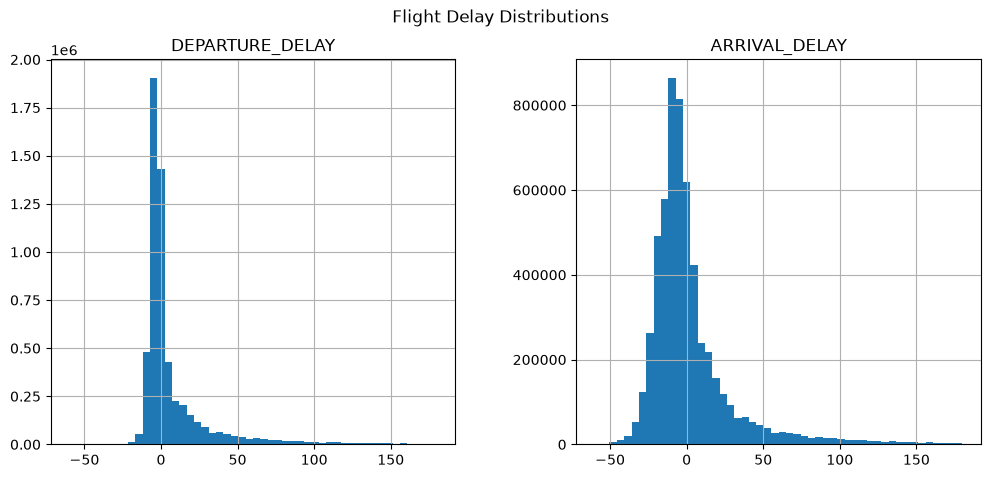

In [9]:
# Plot histograms for departure and arrival delays
flights.hist(
    column=["DEPARTURE_DELAY", "ARRIVAL_DELAY"],
    bins=50,
    figsize=(12, 5),
    range=(-60, 180)
)

# Add a title and display the plots
plt.suptitle("Flight Delay Distributions")
plt.show()

The histograms show that most flights have relatively small departure and arrival delays, while fewer flights experience longer delays. Both distributions are right-skewed, indicating that some flights experience significantly longer delays than the majority.

### 3.2 Boxplots — Departure and Arrival Delays

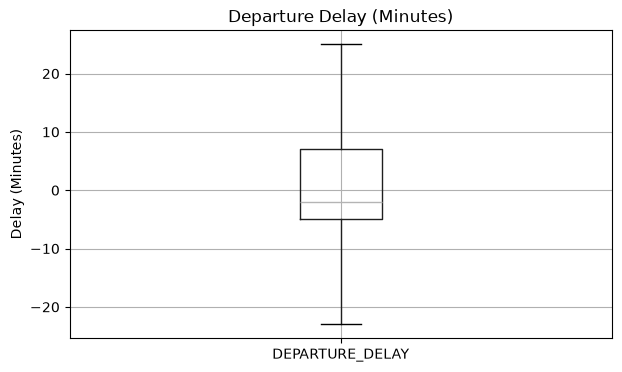

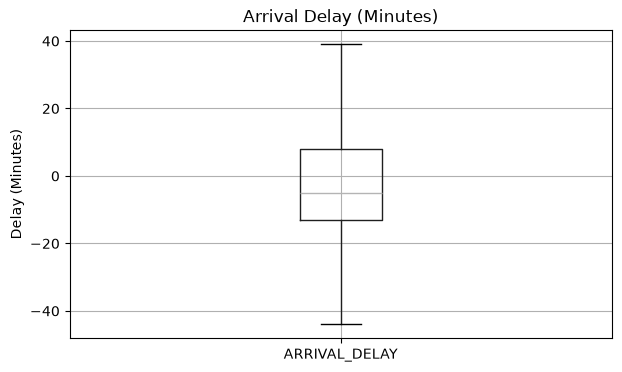

In [10]:
# Plot a boxplot for departure delays
flights.boxplot(
    column="DEPARTURE_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Departure Delay (Minutes)")
plt.ylabel("Delay (Minutes)")
plt.show()

# Plot a boxplot for arrival delays
flights.boxplot(
    column="ARRIVAL_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Arrival Delay (Minutes)")
plt.ylabel("Delay (Minutes)")
plt.show()

The boxplots show the central distribution and variability of departure and arrival delays. The median values and interquartile ranges help compare typical delays and their spread. Extreme values are not displayed because outlier markers have been hidden, allowing the central distributions to be examined more clearly.

### 3.3 Scatter Plot — Departure Delay vs. Arrival Delay

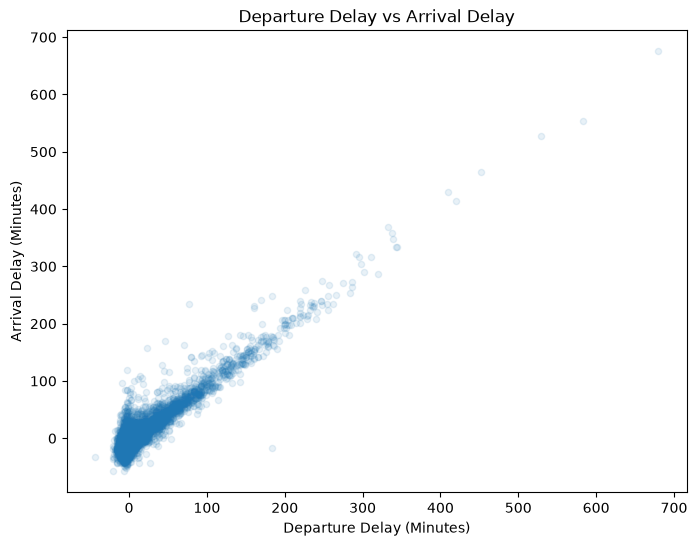

In [11]:
# Select departure and arrival delays and remove missing values
# Use a random sample to improve visualization performance
flight_sample = flights[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].dropna().sample(
    n=10000,
    random_state=42
)

# Plot the relationship between departure and arrival delays
flight_sample.plot(
    kind="scatter",
    x="DEPARTURE_DELAY",
    y="ARRIVAL_DELAY",
    alpha=0.1,
    figsize=(8, 6)
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")
plt.show()

The scatter plot shows a strong positive relationship between departure and arrival delays. Flights with longer departure delays generally experience longer arrival delays. However, some flights may recover or accumulate additional delays during the journey.

## 4. Correlation Between Attributes


### 4.1 Pearson Correlation Matrix

,DEPARTURE_DELAY,ARRIVAL_DELAY,AIR_TIME,DISTANCE,TAXI_OUT,TAXI_IN,SCHEDULED_TIME,ELAPSED_TIME
DEPARTURE_DELAY,1.000000,0.944672,0.023495,0.024106,0.058515,0.012784,0.027799,0.030805
ARRIVAL_DELAY,0.944672,1.000000,-0.007108,-0.025444,0.227319,0.116628,-0.030029,0.029120
AIR_TIME,0.023495,-0.007108,1.000000,0.985643,0.087608,0.082292,0.990749,0.990033
DISTANCE,0.024106,-0.025444,0.985643,1.000000,0.072333,0.075232,0.984336,0.973696
TAXI_OUT,0.058515,0.227319,0.087608,0.072333,1.000000,0.003221,0.112302,0.205195
TAXI_IN,0.012784,0.116628,0.082292,0.075232,0.003221,1.000000,0.099036,0.156179
SCHEDULED_TIME,0.027799,-0.030029,0.990749,0.984336,0.112302,0.099036,1.000000,0.985260
ELAPSED_TIME,0.030805,0.029120,0.990033,0.973696,0.205195,0.156179,0.985260,1.000000


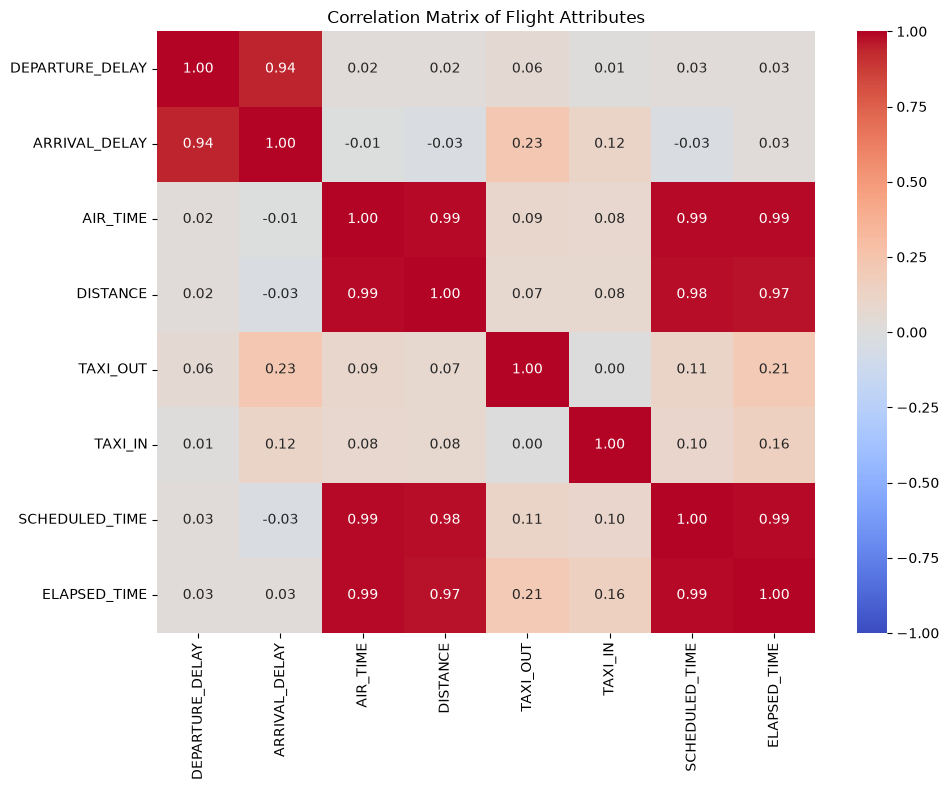

Correlation with ARRIVAL_DELAY:


ARRIVAL_DELAY      1.000000
DEPARTURE_DELAY    0.944672
TAXI_OUT           0.227319
TAXI_IN            0.116628
ELAPSED_TIME       0.029120
AIR_TIME          -0.007108
DISTANCE          -0.025444
SCHEDULED_TIME    -0.030029
Name: ARRIVAL_DELAY, dtype: float64

In [12]:
# Pearson correlation between relevant numerical flight attributes
attributes = [
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "AIR_TIME",
    "DISTANCE",
    "TAXI_OUT",
    "TAXI_IN",
    "SCHEDULED_TIME",
    "ELAPSED_TIME"
]

corr_matrix = flights[attributes].corr(
    numeric_only=True
)

display(corr_matrix)

# Correlation matrix visualization
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Flight Attributes")
plt.tight_layout()
plt.show()

print("Correlation with ARRIVAL_DELAY:")

display(
    corr_matrix["ARRIVAL_DELAY"]
    .sort_values(ascending=False)
)

The correlation matrix shows a very strong positive relationship between departure delay and arrival delay (0.9447), indicating that flights departing late generally tend to arrive late. Air time and distance also have a very strong positive correlation (0.9856). Taxi-out time has a weak positive correlation with arrival delay (0.2273), while distance (-0.0254) and scheduled time (-0.0300) have very weak negative correlations with arrival delay. Correlation measures linear relationships and does not imply causation.

Arrival delay and other arrival-related attributes are included here for exploration only. They are not used as predictors because they are not available at takeoff.

### 4.2 Duplicate Records

Check for exact duplicate flight records before cleaning.

In [13]:
print("Duplicate flight records:", flights.duplicated().sum())

Duplicate flight records: 0


## 5. Data Preprocessing

### 5.1 Data Cleaning and Target Variable

Cancelled and diverted flights are excluded because the model focuses on completed, non-diverted flights. Records without an arrival delay and exact duplicates are removed. The target is 1 for arrival delays of 15 minutes or more and 0 otherwise.

In [14]:
# Check records before cleaning
print("Original flights:", len(flights))
print("Cancelled flights:", (flights["CANCELLED"] == 1).sum())
print("Diverted flights:", (flights["DIVERTED"] == 1).sum())
print("Missing arrival delay:", flights["ARRIVAL_DELAY"].isnull().sum())

# Keep completed flights with known arrival delays
flights_clean = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0) &
    (flights["ARRIVAL_DELAY"].notnull())
].copy()

# Remove exact duplicate records, if any
flights_clean = flights_clean.drop_duplicates()

# Create target: 1 = delayed 15 minutes or more
flights_clean["DELAYED"] = (flights_clean["ARRIVAL_DELAY"] >= 15).astype(int)

print("Remaining flights:", len(flights_clean))
print(flights_clean["DELAYED"].value_counts())
print(flights_clean["DELAYED"].value_counts(normalize=True) * 100)

Original flights: 5819079
Cancelled flights: 89884
Diverted flights: 15187
Missing arrival delay: 105071
Remaining flights: 5714008
DELAYED
0    4650569
1    1063439
Name: count, dtype: int64
DELAYED
0    81.388913
1    18.611087
Name: proportion, dtype: float64


### 5.2 Class Distribution

After cleaning, about 81.39% of flights are not delayed and 18.61% are delayed. This imbalance is addressed during model training.

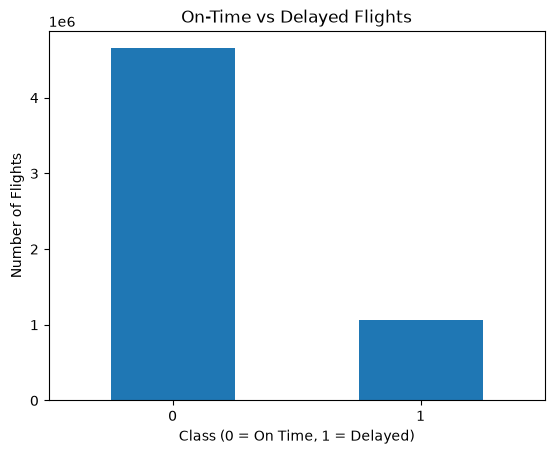

In [15]:
# Show on-time vs delayed flights
flights_clean["DELAYED"].value_counts().sort_index().plot(kind="bar")
plt.title("On-Time vs Delayed Flights")
plt.xlabel("Class (0 = On Time, 1 = Delayed)")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.show()

### 5.3 Feature Selection

We select 14 features available at takeoff. They include flight dates, airline and airport codes, distance, scheduled duration and times, actual departure time, departure delay, taxi-out duration and takeoff time. Time values in HHMM format are converted to minutes after midnight. Arrival delay is used only to define the target. Actual arrival information and delay causes are excluded.

In [16]:
# Convert HHMM times to minutes after midnight
for col in ["SCHEDULED_DEPARTURE", "SCHEDULED_ARRIVAL", "DEPARTURE_TIME", "WHEELS_OFF"]:
    flights_clean[col + "_MIN"] = ((flights_clean[col] // 100) * 60
                                  + flights_clean[col] % 100) % 1440

categorical = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "MONTH", "DAY_OF_WEEK"]
numeric = ["DAY", "DISTANCE", "SCHEDULED_TIME", "SCHEDULED_DEPARTURE_MIN",
           "SCHEDULED_ARRIVAL_MIN", "DEPARTURE_TIME_MIN", "DEPARTURE_DELAY",
           "TAXI_OUT", "WHEELS_OFF_MIN"]
features = numeric + categorical

# Remove records with missing input values
X = flights_clean[features].dropna().copy()
y = flights_clean.loc[X.index, "DELAYED"]
print("Records:", len(X))

Records: 5714008


### 5.4 Dataset Splitting

The data is split into 64% training, 16% validation and 20% testing using stratified sampling. A stratified sample of 100,000 training records reduces the computational cost. Validation is used to select the threshold, and testing is reserved for final evaluation.

In [17]:
# Split the data and select a training sample
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.2, stratify=y_dev, random_state=42)
X_sample, _, y_sample, _ = train_test_split(
    X_train, y_train, train_size=100000, stratify=y_train, random_state=42)

print("Training sample:", len(X_sample))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training sample: 100000
Validation: 914242
Testing: 1142802


### 5.5 Encoding, Scaling and Class Imbalance

Numerical features are standardized and categorical features are encoded. SMOTENC generates synthetic delayed-flight records while preserving categorical values. One-hot encoding is then applied before Logistic Regression. All fitted preprocessing and oversampling take place within the training pipeline; validation and test records are not oversampled.

In [18]:
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline

# Prepare numerical and categorical features for SMOTENC
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric),
    ("categorical", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)
])
cat_indices = list(range(len(numeric), len(features)))
encoder = ColumnTransformer([
    ("numeric", "passthrough", list(range(len(numeric)))),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_indices)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTENC(categorical_features=cat_indices, random_state=42)),
    ("encoding", encoder),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

## 6. Logistic Regression

Three-fold stratified cross-validation is used to assess the model on the training sample. Each fold fits its own preprocessing and oversampling steps. The model is then trained on the full training sample.

In [19]:
# Cross-validation on the training sample
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(model, X_sample, y_sample, cv=cv, scoring="f1")
print("F1 scores:", scores)
print("Mean F1:", scores.mean())

model.fit(X_sample, y_sample)

F1 scores: [0.81762963 0.81385346 0.81676094]
Mean F1: 0.816081342111199


,steps,"[('preprocessing', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](14,)","['DAY','DISTANCE','SCHEDULED_TIME',...,'DESTINATION_AIRPORT','MONTH', 'DAY_OF_WEEK']"
n_features_in_,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


### 6.1 Classification Threshold

We select the probability threshold that gives the highest F1-score on the validation set. The test set is not used for threshold selection.

In [20]:
# Select the threshold using validation predictions
from sklearn.metrics import precision_recall_curve

val_probabilities = model.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_probabilities)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)
best_threshold = thresholds[np.argmax(f1)]
print("Selected threshold:", round(best_threshold, 4))
print("Validation F1:", round(f1.max(), 4))

Selected threshold: 0.7413
Validation F1: 0.8436


### 6.2 Model Evaluation

The model is evaluated on the test set using the selected threshold. Accuracy measures overall correctness, precision measures how many predicted delays are actual delays, and recall measures how many actual delays are detected. F1-score balances precision and recall. Average precision summarizes precision-recall performance across thresholds. The confusion matrix shows correct and incorrect predictions for each class.

Accuracy: 0.9438
Precision: 0.8709
Recall: 0.8196
F1-score: 0.8445
Average precision: 0.9202


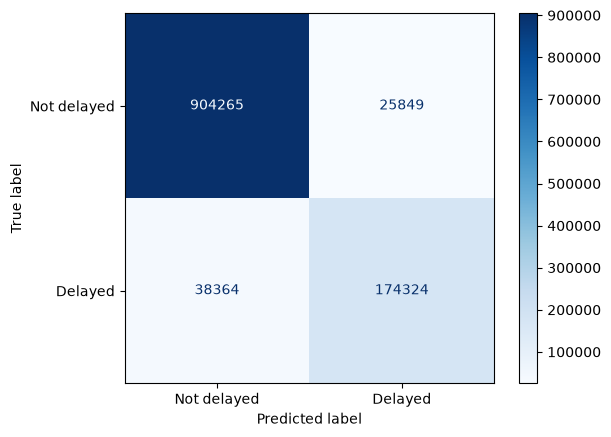

In [21]:
# Evaluate the final model on unseen test records
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, ConfusionMatrixDisplay)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= best_threshold).astype(int)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, predictions), 4))
print("F1-score:", round(f1_score(y_test, predictions), 4))
print("Average precision:", round(average_precision_score(y_test, probabilities), 4))

ConfusionMatrixDisplay.from_predictions(y_test, predictions,
    display_labels=["Not delayed", "Delayed"], cmap="Blues", values_format="d")
plt.show()

## 7. Conclusion

Logistic Regression achieved 94.38% accuracy, 87.09% precision, 81.96% recall and an F1-score of 0.8445. The mean cross-validation F1-score was 0.8161, and the validation F1-score was 0.8436. The close validation and test results indicate consistent performance on held-out records.

Departure-related information is useful for predicting arrival delays at takeoff. The model identifies most delayed flights while keeping false positives relatively low. These results apply to completed, non-diverted flights from the 2015 dataset. Performance on future flight periods has not been tested.